# NHL: анализ статистики команд

**Тестовое задание • 100 баллов**

Вы аналитик, которому передали готовую таблицу с исторической статистикой команд NHL.
Изучите данные, проверьте их, постройте графики и объясните свои наблюдения.
В работе оцениваются чтение данных, анализ, графики и обоснованность выводов.

Ориентир времени: 3-5 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами разместите на платформе githib.com.
Укажите имя, дату и используемые инструменты укажите в README.
Файл `data/hockey_raw.csv` уже приложен к заданию. Исходный файл сохраняйте без изменений.
Для развёрнутого ответа обычно достаточно 3-6 содержательных предложений.
Каждый такой ответ должен ссылаться на ваши числа, строки или графики.

## Данные

Одна строка соответствует одной команде в одном сезоне. Значение `year` является
меткой сезона на сайте. Источник готовой таблицы:
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/).
Работайте с приложенным CSV; обращения к сайту для выполнения задания не нужны.

| Столбец | Значение |
|---|---|
| `team` | Название команды |
| `year` | Метка сезона |
| `wins` | Победы |
| `losses` | Поражения |
| `ot_losses` | Поражения в дополнительное время, если значение указано |
| `win_rate` | Доля побед, указанная в источнике |
| `goals_for` | Забитые шайбы |
| `goals_against` | Пропущенные шайбы |
| `goal_diff` | Разница забитых и пропущенных шайб |

Пустое значение в `ot_losses` рассматривайте как пропуск.
Для графиков указывайте заголовок и подписи осей с единицами измерения.
При объяснении причин отделяйте то, что видно в таблице, от предположений.

## Баллы

| Раздел | Баллы |
|---|---:|
| 1. Загрузка и проверка | 25 |
| 2. Таблицы и группировка | 25 |
| 3. Графики | 30 |
| 4. Интерпретация | 20 |
| **Всего** | **100** |

Выполняйте пункты по порядку. Каждый пункт оценивается отдельно.

**Автор:** Габбасов Ранис Русланович
**Дата:** 13.10.2026  
**Использованные источники и инструменты:** Python, pandas, matplotlib, документация pandas и matplotlib. Код и черновики ответов подготовлены с помощью ИИ-ассистента Claude (Anthropic), весь код и черновики проверены, отвечаю за понимание и правильность работы. Я проанализировал сгенерированные ячейки кода и контролировал что за что отвечает. Понимаю и могу объяснить каждую строчку кода.
 Также проанализировал ответы ассистента. Все результаты воспроизводятся запуском этого ноутбука.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# также я не нашел прикрепленного файла, поэтому пришлось делать код чтобы отпарсить сайт, таким образом получил фпйл hockey_raw.csv:
# import io
# import pandas as pd
# import requests
#
# frames = []
# for p in range(1, 7):
#     r = requests.get(
#         "https://www.scrapethissite.com/pages/forms/",
#         params={"page_num": p, "per_page": 100},
#         timeout=30,
#     )
#     frames.append(pd.read_html(io.StringIO(r.text))[0])
#
# df = pd.concat(frames, ignore_index=True)
# df.columns = ["team", "year", "wins", "losses", "ot_losses",
#               "win_rate", "goals_for", "goals_against", "goal_diff"]
#
# import os
# os.makedirs("data", exist_ok=True)
# df.to_csv("data/hockey_raw.csv", index=False)
# print(df.shape)

SyntaxError: invalid syntax (3762983128.py, line 12)

## 1.1. Загрузите таблицу: 5 баллов

Прочитайте приложенный CSV в pandas. Покажите первые пять строк,
        число строк и столбцов. Какие наблюдения представляет одна строка?

In [5]:
df = pd.read_csv('hockey_raw.csv')
print(df.head(5))
print(df.shape)

                 team  year  wins  losses  ot_losses  win_rate  goals_for  goals_against  goal_diff
0       Boston Bruins  1990    44      24        NaN     0.550        299            264         35
1      Buffalo Sabres  1990    31      30        NaN     0.388        292            278         14
2      Calgary Flames  1990    46      26        NaN     0.575        344            263         81
3  Chicago Blackhawks  1990    49      23        NaN     0.613        284            211         73
4   Detroit Red Wings  1990    34      38        NaN     0.425        273            298        -25
(582, 9)


**Ответ 1.1:**

В таблице 582 строки и 9 столбцов (Команда d.shape на 5 строчке это показывает). Одна строка описывает одну команду в одном сезоне, например Boston Bruins в 1990 году: 44 победы, 24 поражения, `win_rate` 0.55. Заметил, что во всех пяти строках ot_losses пустой

## 1.2. Разберитесь со столбцами: 6 баллов

Выведите названия и типы столбцов. Посчитайте число разных команд и годов.
        Проверьте, повторяется ли пара `team` и `year`. Объясните результат проверки.

In [6]:
print(df.dtypes)
print('команд:', df['team'].nunique())
print('годов:', df['year'].nunique())
print('повторов пары team + year:', df.duplicated(subset=['team', 'year']).sum())

team                 str
year               int64
wins               int64
losses             int64
ot_losses        float64
win_rate         float64
goals_for          int64
goals_against      int64
goal_diff          int64
dtype: object
команд: 35
годов: 21
повторов пары team + year: 0


**Ответ 1.2:**

`team` имеет строковый тип, `year`, `wins`, `losses`, `goals_for`, `goals_against` и `goal_diff` целочисленные, а `win_rate` и `ot_losses` вещественные (у `ot_losses` из-за пропусков). В таблице 35 разных команд и 21 разный год. Повторов пары `team` + `year` нет: `duplicated` дал 0, поэтому пара однозначно определяет строку. При этом 35 × 21 = 735, а строк 582, то есть не каждая команда есть в каждом году.

## 1.3. Найдите пропуски: 8 баллов

Посчитайте число и долю пропусков по столбцам. Для `ot_losses` покажите
        число пропусков по годам. Как будете обращаться с этим полем в дальнейшем анализе
        и почему?

In [7]:
miss = df.isna().sum()
print(pd.DataFrame({'пропусков': miss, 'доля': (miss / len(df)).round(3)}))
print()
ot_by_year = pd.DataFrame({
    'строк': df.groupby('year').size(),
    'пропусков ot_losses': df.groupby('year')['ot_losses'].apply(lambda s: s.isna().sum())
})
print(ot_by_year)

               пропусков   доля
team                   0  0.000
year                   0  0.000
wins                   0  0.000
losses                 0  0.000
ot_losses            224  0.385
win_rate               0  0.000
goals_for              0  0.000
goals_against          0  0.000
goal_diff              0  0.000

      строк  пропусков ot_losses
year                            
1990     21                   21
1991     22                   22
1992     24                   24
1993     26                   26
1994     26                   26
1995     26                   26
1996     26                   26
1997     26                   26
1998     27                   27
1999     28                    0
2000     30                    0
2001     30                    0
2002     30                    0
2003     30                    0
2005     30                    0
2006     30                    0
2007     30                    0
2008     30                    0
2009     30        

**Ответ 1.3:**

Пропуски есть только в `ot_losses`: 224 из 582 строк, то есть 38.5%. По таблице по годам видно, что поле пустое у всех команд с 1990 по 1998 год (224 строки), а с 1999 года заполнено полностью. Значит, это не случайные пропуски: в эти годы показатель, судя по всему, просто не вёлся. Я не буду заменять их нулём или средним, потому что это выдумало бы данные. В анализе я не использую `ot_losses`, а если понадобится, то только для 1999 года и позже.

## 1.4. Проверьте согласованность: 6 баллов

Проверьте, что `win_rate` лежит между 0 и 1, счётчики побед и голов
        неотрицательны, а `goal_diff` равен `goals_for - goals_against`.
        Сообщите, сколько строк нарушает каждое условие. Как бы вы поступили,
        если бы обнаружили нарушение?

In [8]:
print('win_rate вне [0, 1]:', ((df['win_rate'] < 0) | (df['win_rate'] > 1)).sum())
for col in ['wins', 'losses', 'goals_for', 'goals_against']:
    print(col, '< 0:', (df[col] < 0).sum())
print('goal_diff != goals_for - goals_against:', (df['goal_diff'] != df['goals_for'] - df['goals_against']).sum())

win_rate вне [0, 1]: 0
wins < 0: 0
losses < 0: 0
goals_for < 0: 0
goals_against < 0: 0
goal_diff != goals_for - goals_against: 0


**Ответ 1.4:**

Все три проверки пройдены: `win_rate` вне диапазона [0, 1] у 0 строк, отрицательных значений в `wins`, `losses`, `goals_for` и `goals_against` нет (0 в каждом столбце), `goal_diff` совпадает с `goals_for - goals_against` во всех строках (0 нарушений). Если бы нарушения были, я бы сначала посмотрел на эти строки и сравнил их с источником. Молча исправлять не стал бы: либо поправил значение по источнику, либо исключил строку и написал об этом в выводах.

## 2.1. Опишите долю побед: 6 баллов

Найдите минимум, медиану, среднее и максимум `win_rate` по всей таблице.
        Сравните медиану и среднее. Что эти числа сообщают о типичном командном сезоне,
        а чего по ним узнать нельзя?

In [9]:
print(df['win_rate'].agg(['min', 'median', 'mean', 'max']).round(4))

min       0.1190
median    0.4630
mean      0.4585
max       0.7560
Name: win_rate, dtype: float64


**Ответ 2.1:**

Минимум `win_rate` 0.119, медиана 0.463, среднее 0.4585, максимум 0.756. Медиана немного выше среднего, значит, распределение почти симметричное, с небольшим хвостом в сторону низких значений. Типичная команда в сезоне выигрывает чуть меньше половины матчей. Эти числа не говорят, какие команды и годы дают крайние значения, как доля меняется со временем и сколько матчей было сыграно.

## 2.2. Сравните сезоны: 8 баллов

Для каждого года посчитайте число команд, медиану `wins` и медиану `win_rate`.
        Выведите таблицу целиком и отдельно сравните 1993, 1994 и 1995 годы.
        Как отличается картина по числу побед и по доле побед?

In [10]:
by_year = df.groupby('year').agg(
    teams=('team', 'count'),
    median_wins=('wins', 'median'),
    median_win_rate=('win_rate', 'median')
)
print(by_year)
print()
print(by_year.loc[[1993, 1994, 1995]])
print()
print('медиана wins + losses:')
print((df['wins'] + df['losses']).groupby(df['year']).median().loc[[1993, 1994, 1995]])

      teams  median_wins  median_win_rate
year                                     
1990     21         34.0           0.4250
1991     22         35.5           0.4440
1992     24         40.0           0.4760
1993     26         39.0           0.4640
1994     26         20.5           0.4275
1995     26         35.5           0.4330
1996     26         35.0           0.4270
1997     26         35.0           0.4270
1998     27         34.0           0.4150
1999     28         36.0           0.4390
2000     30         36.5           0.4450
2001     30         37.0           0.4510
2002     30         35.5           0.4330
2003     30         38.0           0.4630
2005     30         42.0           0.5120
2006     30         42.5           0.5180
2007     30         41.5           0.5060
2008     30         41.0           0.5000
2009     30         40.0           0.4880
2010     30         43.0           0.5240
2011     30         41.0           0.5000

      teams  median_wins  median_

**Ответ 2.2:**

Медиана `wins` в 1993 году 39.0, в 1994 году 20.5, в 1995 году 35.5, а медиана `win_rate` 0.464, 0.4275 и 0.433. По числу побед 1994 год выглядит почти вдвое хуже, а по доле побед отличается от 1993 всего на 0.037. В таблице видно причину: медиана `wins + losses` в 1994 году 43 против 73 в 1993 и 71.5 в 1995, то есть команды сыграли заметно меньше матчей. Почему сезон был короче, таблица не говорит, но для сравнения сезонов доля побед надёжнее, чем число побед.

## 2.3. Найдите крайние результаты: 5 баллов

Покажите три строки с самой высокой и три с самой низкой `win_rate`.
        Укажите команду, год и значение. Как вы убедились, что сравниваете именно долю,
        а не число побед?

In [11]:
cols = ['team', 'year', 'win_rate', 'wins']
print(df.nlargest(3, 'win_rate')[cols])
print()
print(df.nsmallest(3, 'win_rate')[cols])
print()
print('для сравнения, топ-3 по числу побед:')
print(df.nlargest(3, 'wins')[cols])

                  team  year  win_rate  wins
126  Detroit Red Wings  1995     0.756    62
382  Detroit Red Wings  2005     0.707    58
99   Detroit Red Wings  1994     0.688    33

               team  year  win_rate  wins
56  Ottawa Senators  1992     0.119    10
60  San Jose Sharks  1992     0.131    11
82  Ottawa Senators  1993     0.167    14

для сравнения, топ-3 по числу побед:
                    team  year  win_rate  wins
126    Detroit Red Wings  1995     0.756    62
382    Detroit Red Wings  2005     0.707    58
58   Pittsburgh Penguins  1992     0.667    56


**Ответ 2.3:**

Самые высокие `win_rate`: Detroit Red Wings 1995 (0.756), Detroit Red Wings 2005 (0.707), Detroit Red Wings 1994 (0.688). Самые низкие: Ottawa Senators 1992 (0.119), San Jose Sharks 1992 (0.131), Ottawa Senators 1993 (0.167). Я сортировал именно по столбцу `win_rate` (`nlargest` и `nsmallest`), а не по `wins`. Разница видна в сравнении: топ-3 по победам включает Pittsburgh Penguins 1992 (56 побед), а Detroit 1994 с 33 победами в нём нет, хотя по доле он третий.

## 2.4. Выберите команду: 6 баллов

Выберите команду, представленную не менее чем в пяти сезонах.
        Покажите её строки по годам и найдите сезон с минимальной и максимальной
        долей побед. Почему сравнивать только название команды без года неудобно?

In [12]:
team = 'Detroit Red Wings'
det = df[df['team'] == team].sort_values('year')
print('сезонов:', len(det))
print(det[['year', 'wins', 'losses', 'win_rate']])
print()
print('минимум:', det.loc[det['win_rate'].idxmin(), ['year', 'win_rate']].to_dict())
print('максимум:', det.loc[det['win_rate'].idxmax(), ['year', 'win_rate']].to_dict())

сезонов: 21
     year  wins  losses  win_rate
4    1990    34      38     0.425
25   1991    43      25     0.537
47   1992    47      28     0.560
73   1993    46      30     0.548
99   1994    33      11     0.688
126  1995    62      13     0.756
152  1996    38      26     0.463
179  1997    44      23     0.537
205  1998    43      32     0.524
233  1999    48      22     0.585
262  2000    49      20     0.598
292  2001    51      17     0.622
322  2002    48      20     0.585
352  2003    48      21     0.585
382  2005    58      16     0.707
412  2006    50      19     0.610
442  2007    54      21     0.659
472  2008    51      21     0.622
502  2009    44      24     0.537
532  2010    47      25     0.573
561  2011    48      28     0.585

минимум: {'year': 1990.0, 'win_rate': 0.425}
максимум: {'year': 1995.0, 'win_rate': 0.756}


**Ответ 2.4:**

Я выбрал Detroit Red Wings: у команды 21 сезон, с 1990 по 2011 год, без 2004. Минимальная доля побед 0.425 в 1990 году, максимальная 0.756 в 1995 году. Сравнивать только по названию неудобно: одно название объединяет 21 разный сезон, и без года нельзя понять, какой результат к какому времени относится, например 1994 год с коротким сезоном.

## 3.1. Покажите распределение: 7 баллов

Постройте гистограмму `win_rate` для всех строк.
        Подпишите оси и объясните, в какой части шкалы расположено большинство наблюдений.
        Приведите числовое подтверждение из пункта 2.1.

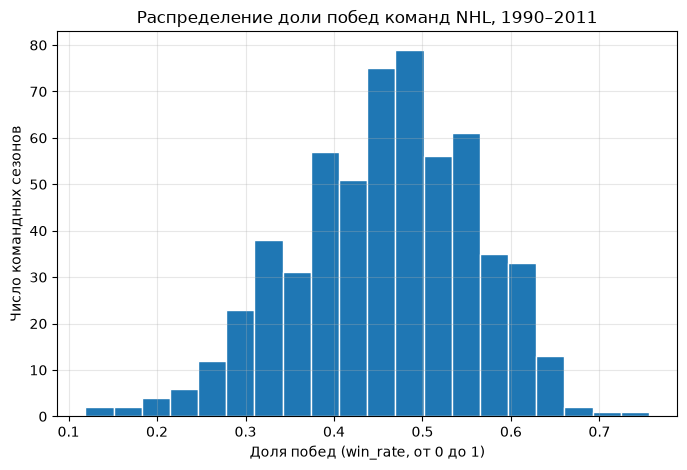

0.25    0.390
0.50    0.463
0.75    0.534
Name: win_rate, dtype: float64


In [13]:
plt.hist(df['win_rate'], bins=20, edgecolor='white')
plt.title('Распределение доли побед команд NHL, 1990–2011')
plt.xlabel('Доля побед (win_rate, от 0 до 1)')
plt.ylabel('Число командных сезонов')
plt.show()
print(df['win_rate'].quantile([0.25, 0.5, 0.75]))

**Ответ 3.1:**

Большинство наблюдений лежит в средней части шкалы, примерно от 0.4 до 0.5, с пиком около медианы. Числа из 2.1 и квартили в ячейке выше это подтверждают: медиана 0.463, первый квартиль 0.39, третий 0.534, то есть половина всех командных сезонов попадает в диапазон 0.39–0.534. Значения ниже 0.2 и выше 0.7 редкие, на гистограмме это тонкие хвосты.

## 3.2. Покажите изменение по годам: 8 баллов

Постройте линейный график медианы `win_rate` по годам из пункта 2.2.
        Подпишите оси. Найдите один год с заметно большей или меньшей медианой,
        чем у соседних доступных лет, и приведите числа. Отметьте в объяснении
        годы без данных.

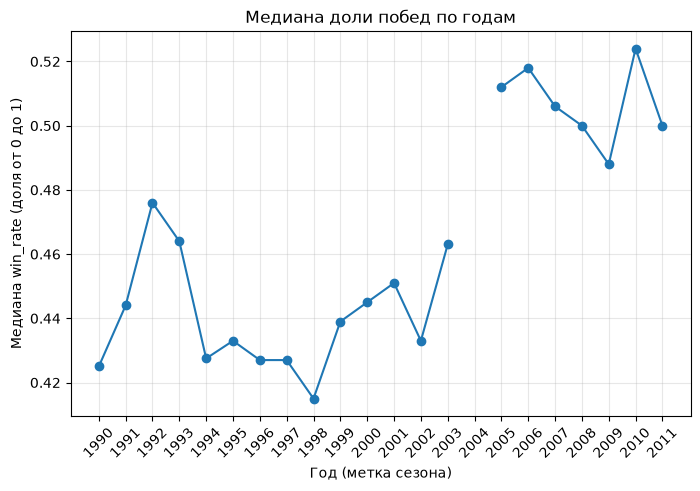

year
2009    0.488
2010    0.524
2011    0.500
Name: median_win_rate, dtype: float64


In [14]:
all_years = list(range(df['year'].min(), df['year'].max() + 1))
med = by_year['median_win_rate'].reindex(all_years)

plt.plot(med.index, med.values, marker='o')
plt.title('Медиана доли побед по годам')
plt.xlabel('Год (метка сезона)')
plt.ylabel('Медиана win_rate (доля от 0 до 1)')
plt.xticks(all_years, rotation=45)
plt.show()
print(med.loc[[2009, 2010, 2011]])

**Ответ 3.2:**

Заметно выше соседей медиана 2010 года: 0.524 против 0.488 в 2009 и 0.500 в 2011. Данных за 2004 год нет, поэтому на графике между 2003 и 2005 годами линия прерывается. Кроме того, видно, что после 2003 года (0.463) медиана в 2005 году (0.512) выходит на уровень около 0.5 и дальше держится в пределах 0.49–0.52.

## 3.3. Сравните голы и долю побед: 8 баллов

Постройте диаграмму рассеяния: `goal_diff` по горизонтали,
        `win_rate` по вертикали. Опишите общую связь и приведите две конкретные
        строки для иллюстрации. Можно ли по этому графику заключить, что знак
        `goal_diff` безошибочно определяет высокую долю побед?

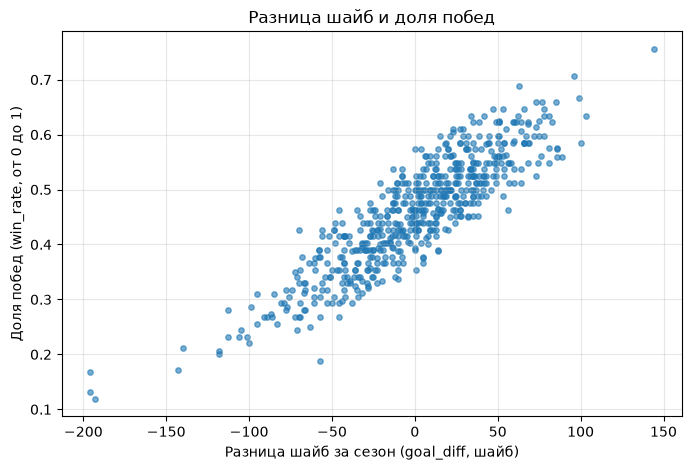

корреляция: 0.887

                  team  year  goal_diff  win_rate
60     San Jose Sharks  1992       -196     0.131
126  Detroit Red Wings  1995        144     0.756

goal_diff > 0: 311
goal_diff > 0 и win_rate < 0.5: 96
goal_diff < 0 и win_rate > 0.5: 10


In [15]:
plt.scatter(df['goal_diff'], df['win_rate'], s=15, alpha=0.6)
plt.title('Разница шайб и доля побед')
plt.xlabel('Разница шайб за сезон (goal_diff, шайб)')
plt.ylabel('Доля побед (win_rate, от 0 до 1)')
plt.show()
print('корреляция:', round(df['goal_diff'].corr(df['win_rate']), 3))
print()
mask = ((df['team'] == 'Detroit Red Wings') & (df['year'] == 1995)) | ((df['team'] == 'San Jose Sharks') & (df['year'] == 1992))
print(df[mask][['team', 'year', 'goal_diff', 'win_rate']])
print()
print('goal_diff > 0:', (df['goal_diff'] > 0).sum())
print('goal_diff > 0 и win_rate < 0.5:', ((df['goal_diff'] > 0) & (df['win_rate'] < 0.5)).sum())
print('goal_diff < 0 и win_rate > 0.5:', ((df['goal_diff'] < 0) & (df['win_rate'] > 0.5)).sum())

**Ответ 3.3:**

Связь прямая и сильная: чем больше `goal_diff`, тем выше `win_rate`, корреляция равна 0.887. Для примера, Detroit Red Wings 1995: `goal_diff` 144, `win_rate` 0.756, а San Jose Sharks 1992: `goal_diff` −196, `win_rate` 0.131. Однако знак `goal_diff` безошибочно не определяет высокую долю побед: из 311 строк с положительным `goal_diff` у 96 доля побед ниже 0.5, а у 10 строк с отрицательным `goal_diff` она выше 0.5.

## 3.4. Покажите историю выбранной команды: 7 баллов

Для команды из пункта 2.4 постройте график `win_rate` по годам.
        Укажите в ответе, есть ли годы без данных, и как вы показали их на графике.
        Найдите два соседних доступных сезона с заметным изменением
        и укажите значения в ответе.

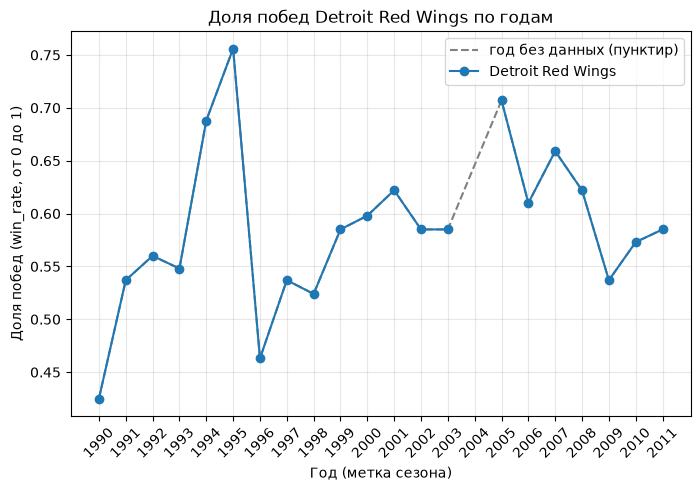

годы без данных: [2004]
year
1996   -0.293
1994    0.140
1991    0.112
Name: win_rate, dtype: float64


In [16]:
det_rate = det.set_index('year')['win_rate'].reindex(range(1990, 2012))

plt.plot(det_rate.dropna().index, det_rate.dropna().values, linestyle='--', color='gray', label='год без данных (пунктир)')
plt.plot(det_rate.index, det_rate.values, marker='o', color='C0', label='Detroit Red Wings')
plt.title('Доля побед Detroit Red Wings по годам')
plt.xlabel('Год (метка сезона)')
plt.ylabel('Доля побед (win_rate, от 0 до 1)')
plt.xticks(range(1990, 2012), rotation=45)
plt.legend()
plt.show()
print('годы без данных:', det_rate[det_rate.isna()].index.tolist())
chg = det_rate.diff()
print(chg.reindex(chg.abs().sort_values(ascending=False).index).head(3).round(3))

**Ответ 3.4:**

У Detroit Red Wings нет данных за 2004 год. На графике этот год оставлен пустым, линия там прерывается, а точки 2003 и 2005 соединены серым пунктиром. Самое заметное изменение между соседними сезонами произошло с 1995 на 1996 год: 0.756 → 0.463 (−0.293). Ещё одно резкое изменение с 1993 на 1994 год: 0.548 → 0.688 (+0.140).

## 4.1. Проверьте последовательность лет: 5 баллов

Найдите все годы между минимальным и максимальным `year`,
        которых нет в таблице. Как отсутствие года может повлиять на линейный график?
        Сошлитесь на свой график из пункта 3.2.

In [17]:
missing = sorted(set(range(df['year'].min(), df['year'].max() + 1)) - set(df['year']))
print('годы без данных:', missing)
print(by_year.loc[[2003, 2005], 'median_win_rate'])

годы без данных: [2004]
year
2003    0.463
2005    0.512
Name: median_win_rate, dtype: float64


**Ответ 4.1:**

Между 1990 и 2011 годами в таблице отсутствует только 2004 год. Если построить линию без учёта этого, 2003 и 2005 годы окажутся соединены как соседние, и пропуск станет незаметен, а скачок медианы с 0.463 до 0.512 будет похож на обычное изменение за один год. В 3.2 я добавил 2004 год как пустое значение, поэтому линия там разрывается. Предположение, которого нет в таблице: в этом году сезон не проводился.

## 4.2. Сравните число побед и долю: 6 баллов

Возьмите одну команду, которая есть в 1993, 1994 и 1995 годах.
        Выведите для неё `wins` и `win_rate` за эти годы.
        Какой вывод изменится, если смотреть только на число побед?
        Свяжите ответ с группировкой из пункта 2.2.

In [18]:
det3 = df[(df['team'] == 'Detroit Red Wings') & (df['year'].isin([1993, 1994, 1995]))]
print(det3[['year', 'wins', 'losses', 'win_rate']])

     year  wins  losses  win_rate
73   1993    46      30     0.548
99   1994    33      11     0.688
126  1995    62      13     0.756


**Ответ 4.2:**

Для Detroit Red Wings: 1993 год 46 побед и `win_rate` 0.548, 1994 год 33 победы и 0.688, 1995 год 62 победы и 0.756. Если смотреть только на победы, 1994 год выглядит ухудшением (46 → 33), хотя доля побед выросла. Это согласуется с группировкой из 2.2: медиана побед по лиге в 1994 году упала до 20.5, а медиана доли побед изменилась мало (0.4275), потому что команды сыграли меньше матчей.

## 4.3. Найдите собственное наблюдение: 5 баллов

Найдите ещё один интересный вам пример в таблице или на графике.
        Укажите команду, год, два значения и пункт, результат которого
        помог вам заметить пример. Как он уточняет ваш общий вывод?

In [19]:
print(df[df['goal_diff'] == -196][['team', 'year', 'goal_diff', 'win_rate']])

               team  year  goal_diff  win_rate
60  San Jose Sharks  1992       -196     0.131
82  Ottawa Senators  1993       -196     0.167


**Ответ 4.3:**

San Jose Sharks 1992 и Ottawa Senators 1993 имеют одинаковый `goal_diff` −196, но `win_rate` у них 0.131 и 0.167. Заметил я это, глядя на самые низкие значения в 2.3 и на диаграмму из 3.3. Пример уточняет общий вывод: связь между разницей шайб и долей побед сильная, но не жёсткая, при одинаковой разнице шайб доля побед может отличаться.

## 4.4. Сформулируйте выводы: 4 баллов

Сформулируйте два вывода из своей работы. Для каждого приведите
        номер таблицы или графика и одно число. Назовите одно ограничение данных,
        которое важно помнить при чтении результатов.

In [20]:
print('корреляция goal_diff и win_rate:', round(df['goal_diff'].corr(df['win_rate']), 3))
print(by_year.loc[[2003, 2005], 'median_win_rate'])
print('доля пропусков ot_losses:', round(df['ot_losses'].isna().mean(), 3))

корреляция goal_diff и win_rate: 0.887
year
2003    0.463
2005    0.512
Name: median_win_rate, dtype: float64
доля пропусков ot_losses: 0.385


**Ответ 4.4:**

Вывод 1: доля побед тесно связана с разницей шайб, на диаграмме 3.3 корреляция равна 0.887. Вывод 2: после перерыва в 2004 году медиана доли побед выросла с 0.463 в 2003 году до 0.512 в 2005 году (таблица 2.2, график 3.2) и осталась около 0.5. Ограничение: в таблице нет числа сыгранных матчей, поэтому счётчики вроде `wins` не сопоставимы между сезонами (1994 год), а `ot_losses` пуст для 38.5% строк.